# 04 First order conduit stats

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from os.path import exists, split, join
from os import makedirs
from tqdm import tqdm
from matplotlib.gridspec import GridSpec
from stl import mesh
import base.geometry as geom

from matplotlib.cm import tab20b
from base.utils import list_all_centrelines, return_centreline_parametrisation, list_all_plymeshes, plotDescriptor, plot_autocovariance, plot_autocorrelation_coefficients

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
# change here the path to the repository of karst catalogue
data_repository = "F:/ScanLeica/data_paper/KarstConduitCatalogue" 
#data_repository = "D:/KarstConduitCatalogue"
centreline_filepaths = list_all_centrelines(data_repository)

In [3]:
centreline_filepaths

['F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\Archamps\\PostEtroiture\\geometric_descriptors\\Archamps_PostEtroiture_centreline.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\Archamps\\PreEtroiture\\geometric_descriptors\\Archamps_PreEtroiture_centreline.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\BaumeDeLongeaigue\\GrandToboggan\\geometric_descriptors\\BaumeDeLongeaigue_GrandToboggan_centreline.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CascadeDeMotiers\\MainGallery\\geometric_descriptors\\CascadeDeMotiers_MainGallery_centreline.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CocaliereCotepatiere\\AvenDeLaCocaliere1\\geometric_descriptors\\CocaliereCotepatiere_AvenDeLaCocaliere1_centreline.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CocaliereCotepatiere\\AvenDeLaCocaliere2\\geometric_descriptors\\CocaliereCotepatiere_AvenDeLaCocaliere2_centreline.txt',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CocaliereCot

We now select a specific cave passage and read out the section information, including the geometric descriptors.

In [4]:
idx = 21
INSET_SIZE = 10
start = 0
end = -1

sections_directory = join(split(centreline_filepaths[idx])[0], "sections")
stub = len("_centreline.txt")
thecavepassage = split(centreline_filepaths[idx])[1][:-stub]

Now we can find and load the geometric descriptors calculated on the relevant sections. 

In [5]:
descriptors_filepath = join(split(centreline_filepaths[idx])[0], "section_descriptors.txt")
conduit_descriptors = np.loadtxt(descriptors_filepath, delimiter=" ", skiprows=1)
with open(descriptors_filepath, "r") as f:
    header = f.readline()[2:-1].split(",")
    f.close()

In [6]:
meshes_filepaths = list_all_plymeshes(data_repository)
meshdata = mesh.Mesh.from_file(meshes_filepaths[idx][:-3] + "stl")

Since we have twenty descriptors, we can have a look at all descriptors in a matrix of histograms. 

We let $\Omega$ be the section object, with an outer contour called $p$ after `doi.org/10.1021/acscatal.5b02628`

$A = card(x) \mid x \in \Omega$

$P = \sum_{x \in p}{V(x)}, \text{V local weighting function}$

$L = max\left\Vert x_1 - x_2 \right\Vert x_1 \in p, x_2 \in p, x1 \neq x_2$

$r_{min}  = min\left\Vert x - c \right\Vert \mid x \in p$

$r_{max}  = max\left\Vert x - c \right\Vert \mid x \in p$

$r_{ave} = \frac{1}{card(p)} \sum_{x \in p}{\left\Vert x - c \right\Vert} $

$D_{H} = \frac{4A}{P}$

$\gamma_1 = \frac{r_{min}}{r_{max}}$

$\gamma_2 = \frac{P^2}{A}$

$\gamma_c = \frac{P}{2 \sqrt{\pi A}}$

$\gamma_3 = \frac{r_{max} - r_{min}}{r_{max}}$

$\delta_{inscribed} = \frac{\pi r_{min}^2}{A}$

$\delta_{circumscribed} = \frac{\pi r_{max}^2}{A}$

$E = \frac{4}{\pi} \frac{A}{{r_{ave}}^2}$

$d_{iso} = \frac{4 \pi A}{p^2}$

$\gamma_M = \frac{4}{\pi} \frac{A}{L^2}$

$\sigma^2_{circ} = \frac{\sum_{x \in \Omega}{(\left \Vert x - c \right \Vert -r_{ave})^2}}{Ar_{ave}^2}$

$S = \frac{card(x_1)}{card(x_2)} \mid x_1 \in \Omega, x_2 \in \mathcal{C}(\Omega)$

In [7]:
header

['area',
 'ellipse_aspect_ratio',
 'ellipse_rotation',
 'perimeter',
 'solidity',
 'hydraulic_diameter',
 'max_chord_length',
 'rmax',
 'rmin',
 'r_average',
 'circularity',
 'circularity2',
 'gravelius_compactness',
 'circularity3',
 'deviation_from_inscribed_disk',
 'deviation_from_circumscribed_disk',
 'elongation',
 'isoperimetric_deficiency',
 'morton_spreading_index',
 'circular_variance',
 'is_closed',
 'curvilinear_coord']

In [8]:
centreline_filepaths = list_all_centrelines(data_repository)
centreline_filepath = centreline_filepaths[idx]
assert exists(centreline_filepath)
centreline = np.loadtxt(centreline_filepath, skiprows=1)

interpolated_centreline, curvilinear_coords, normed_vectors = return_centreline_parametrisation(centreline, dt=0.5)

# too tortuous vectors, removed from calculation... 
ignore_calc = np.hstack(([False],  np.linalg.norm(np.diff(normed_vectors, axis=0), axis = 1) > 0.2))
np.savetxt(join(sections_directory, "ignore_flags.txt"), ignore_calc)

sections = [np.loadtxt(join(sections_directory, f"s{c}.txt"), skiprows=1) for c in range(len(normed_vectors))]
sections2d = [geom.to2D(section, nP) for section, nP, remove in zip(sections, normed_vectors, ignore_calc) if not remove]

In [9]:
attributes = [0, 3, 5]
n_attr = len(attributes)

## autocorrelation function for a given descriptor. 

ACF = E[XXbar]

In [10]:
dt = 0.5
maxlag = np.floor(conduit_descriptors[-1, -1] / (2*dt)).astype(int)


ValueError: array must not contain infs or NaNs

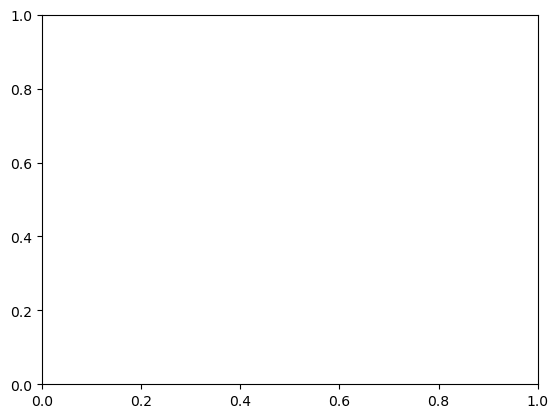

In [11]:
fig, ax = plt.subplots()

plot_autocovariance(ax, conduit_descriptors[:, 1], maxlag, dt, tab20b, attrn=0)
plt.show()

<AxesSubplot:xlabel='lag in samples [m]', ylabel='Autocorrelation function $\\hat{A}^{XX}_j$'>

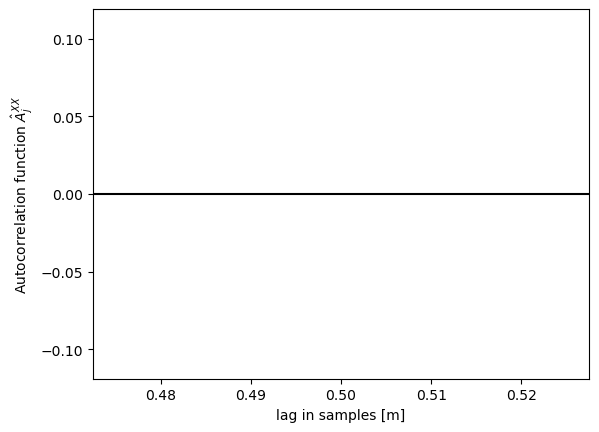

In [12]:
fig, ax = plt.subplots()
dt = 0.5
maxlag = np.floor(conduit_descriptors[-1, -1] / (2*dt)).astype(int)
N = len(conduit_descriptors)
plot_autocorrelation_coefficients(ax, conduit_descriptors[:, 1], maxlag, dt, tab20b, attrn=0)

plotting the dh for section 276 at 7.52m
plotting the dh for section 98 at 2.98m


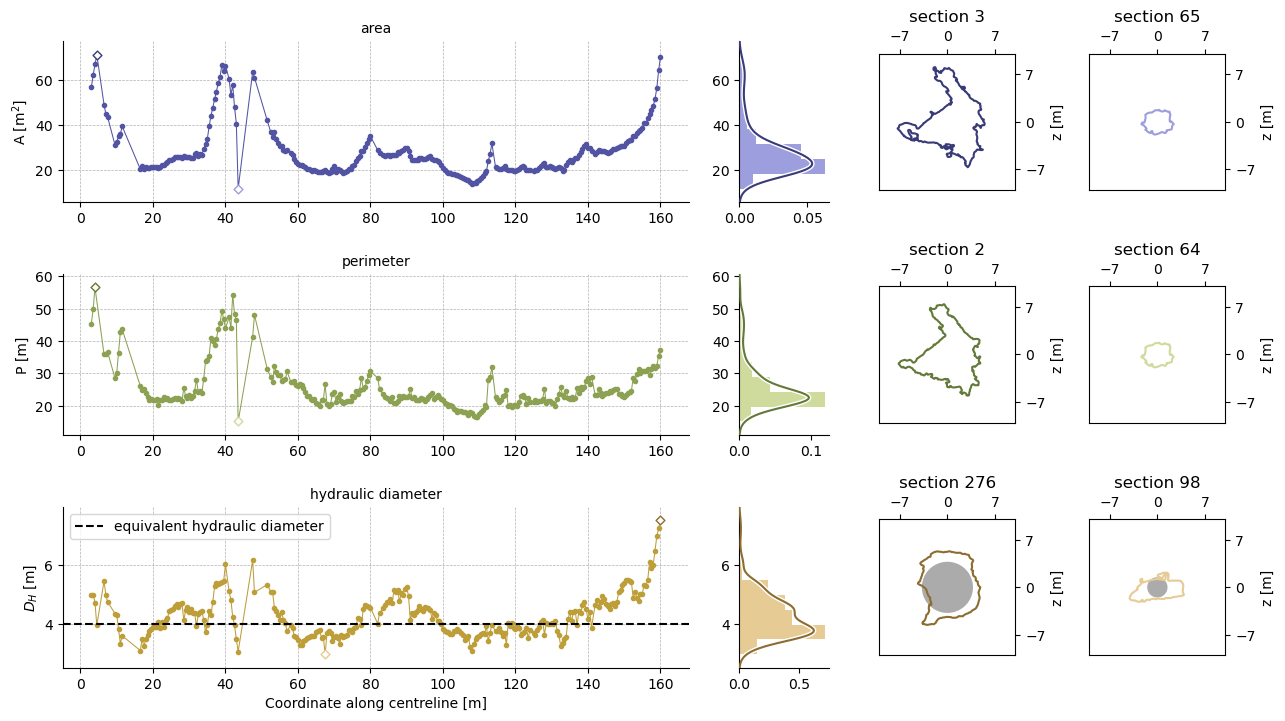

In [13]:
fig = plt.figure(figsize = (15, 3*n_attr))

gs = GridSpec(7*n_attr, 50)


labels = [geom.DESCRIPTOR_MAP[header[elem]]["name"] for elem in attributes]
units = [geom.DESCRIPTOR_MAP[header[elem]]["unit"] for elem in attributes]
abbrs = [geom.DESCRIPTOR_MAP[header[elem]]["abbr"] for elem in attributes]

descriptors = {}

for n, (col, label, unit, abbr) in enumerate(zip(attributes, labels, units, abbrs)):
    i = 7*n
    ax = fig.add_subplot(gs[i:i+5, :27])
    ax.set_ylabel(f"{abbr} [{unit}]")
    ax.set_title(label, fontsize =10)
    
    ax_hist = fig.add_subplot(gs[i:i+5, 29:33], sharey = ax)
    
    ax_inset1 = fig.add_subplot(gs[i:i+5, 35:41])
    ax_inset2 = fig.add_subplot(gs[i:i+5, 44:], sharex = ax_inset1, sharey = ax_inset1)
    
    last = False
    if n == len(attributes) -1:
        last = True

    
    plotDescriptor(sections2d[start:end], conduit_descriptors[~ignore_calc][start:end],header, col, ax, ax_hist, ax_inset1, ax_inset2, inset_size=INSET_SIZE, last = last, attr_n=n)

plt.savefig(f"./temp/barcelona_figures/curvilinear_attributes_{thecavepassage}_{'_'.join([str(elem) for elem in attributes])}.png")

80


ValueError: array must not contain infs or NaNs

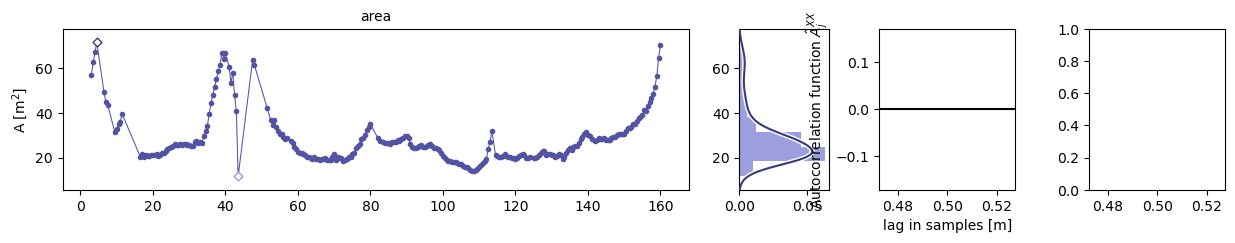

In [14]:
fig = plt.figure(figsize = (15, 3*n_attr))

gs = GridSpec(7*n_attr, 50)


labels = [geom.DESCRIPTOR_MAP[header[elem]]["name"] for elem in attributes]
units = [geom.DESCRIPTOR_MAP[header[elem]]["unit"] for elem in attributes]
abbrs = [geom.DESCRIPTOR_MAP[header[elem]]["abbr"] for elem in attributes]

descriptors = {}

for n, (col, label, unit, abbr) in enumerate(zip(attributes, labels, units, abbrs)):
    i = 7*n
    ax = fig.add_subplot(gs[i:i+5, :27])
    ax.set_ylabel(f"{abbr} [{unit}]")
    ax.set_title(label, fontsize =10)
    
    ax_hist = fig.add_subplot(gs[i:i+5, 29:33], sharey = ax)
    
    ax_inset1 = fig.add_subplot(gs[i:i+5, 35:41])
    ax_inset2 = fig.add_subplot(gs[i:i+5, 44:], sharex = ax_inset1)
    
    last = False
    if n == len(attributes) -1:
        last = True

    plotDescriptor(sections2d[start:end], conduit_descriptors[~ignore_calc][start:end],header, col, ax, ax_hist, ax_inset1, ax_inset2, 
                   inset_size=INSET_SIZE, last = last, attr_n=n, with_autocovariance=True)
    

plt.savefig(f"./temp/barcelona_figures/curvilinear_attributes_{thecavepassage}_{'_'.join([str(elem) for elem in attributes])}_auto_cov.png")

In [ ]:
fig = plt.figure(figsize = (15, 3*n_attr))

gs = GridSpec(7*n_attr, 50)

# now we workout the ratio of yrange to zrange
_, yrange, zrange = np.max(meshdata.centroids, axis = 0) - np.min(meshdata.centroids, axis = 0)

frac_plan =int(0.9* np.floor(yrange / (yrange+zrange) * (7*n_attr)))

axmap_plan = fig.add_subplot(gs[:frac_plan, :26])
axmap_elev = fig.add_subplot(gs[frac_plan+1:-1, :26])

for axmap, secondcoord, ylabel in zip((axmap_plan, axmap_elev), (1, 2) ,"yz"):
    axmap.scatter(*meshdata.centroids[::500, [0, secondcoord]].T, color= "lightgrey", s=2)
    axmap.set_aspect("equal")
    axmap.set_xlabel("x [m]")
    axmap.set_ylabel(f"{ylabel} [m]")

    axmap.scatter(*interpolated_centreline[:, [0, secondcoord]].T, color = "k", s=2)
    for section in sections:
        axmap.plot(*section[:, [0, secondcoord]].T, color = "deeppink", lw = 0.5)

labels = [geom.DESCRIPTOR_MAP[header[elem]]["name"] for elem in attributes]
units = [geom.DESCRIPTOR_MAP[header[elem]]["unit"] for elem in attributes]
abbrs = [geom.DESCRIPTOR_MAP[header[elem]]["abbr"] for elem in attributes]

descriptors = {}

for n, (col, label, unit, abbr) in enumerate(zip(attributes, labels, units, abbrs)):
    i = 7*n
    ax = None

    # plot the relevant sections.
    themin_section = sections[np.argmin(conduit_descriptors[~ignore_calc, col][start:end])]
    themax_section = sections[np.argmax(conduit_descriptors[~ignore_calc, col][start:end])]

    for axmap, secondcoord in zip((axmap_plan, axmap_elev), (1, 2)):
        axmap.plot(*themin_section[:, [0,secondcoord]].T, color = tab20b(4*n+3), lw = 2, zorder = 11)
        axmap.plot(*themin_section[:, [0,secondcoord]].T, color = "white", lw = 3.5, zorder = 10)

        axmap.plot(*themax_section[:, [0,secondcoord]].T, color = tab20b(4*n), lw = 2, zorder = 11)
        axmap.plot(*themax_section[:, [0,secondcoord]].T, color = "white", lw = 3.5, zorder = 10)
    
    ax_hist = fig.add_subplot(gs[i:i+5, 29:33], sharey = ax)
    ax_hist.set_ylabel(f"{abbr} [{unit}]")
    ax_hist.set_title(label, fontsize =10)
    ax_inset1 = fig.add_subplot(gs[i:i+5, 35:41])
    ax_inset2 = fig.add_subplot(gs[i:i+5, 44:], sharex = ax_inset1, sharey = ax_inset1)
    
    last = False
    
    plotDescriptor(sections2d[start:end], conduit_descriptors[~ignore_calc][start:end],header, col, ax, ax_hist, ax_inset1, ax_inset2, inset_size=INSET_SIZE, 
                   last = last, 
                   withmap=True, attr_n=n)

plt.savefig(f"./temp/barcelona_figures/curvilinear_{thecavepassage}_attributes_{'_'.join([str(elem) for elem in attributes])}_withmap.png")

In [ ]:
attributes = [4, 1, 12]
n_attr = len(attributes)

In [ ]:
fig = plt.figure(figsize = (15, 3*n_attr))

gs = GridSpec(7*n_attr, 50)

labels = [geom.DESCRIPTOR_MAP[header[elem]]["name"] for elem in attributes]
units = [geom.DESCRIPTOR_MAP[header[elem]]["unit"] for elem in attributes]
abbrs = [geom.DESCRIPTOR_MAP[header[elem]]["abbr"] for elem in attributes]

descriptors = {}

for n, (col, label, unit, abbr) in enumerate(zip(attributes, labels, units, abbrs)):
    i = 7*n
    print(i)
    ax = fig.add_subplot(gs[i:i+5, :27])
    ax.set_ylabel(f"{abbr} [{unit}]")
    ax.set_title(label, fontsize =10)
    
    ax_hist = fig.add_subplot(gs[i:i+5, 29:33], sharey = ax)
    
    ax_inset1 = fig.add_subplot(gs[i:i+5, 35:41])
    ax_inset2 = fig.add_subplot(gs[i:i+5, 44:], sharex = ax_inset1, sharey = ax_inset1)
    
    last = False
    if n == len(attributes) -1:
        last = True
    
    plotDescriptor(sections2d, conduit_descriptors[~ignore_calc],header, col, ax, ax_hist, ax_inset1, ax_inset2, inset_size=INSET_SIZE, last = last, attr_n=n)

plt.savefig(f"./temp/barcelona_figures/curvilinear_attributes_{thecavepassage}_{'_'.join([str(elem) for elem in attributes])}.png")

In [ ]:
attributes = [7, 8, 11]
n_attr = len(attributes)

In [ ]:
fig = plt.figure(figsize = (15, 3*n_attr))

gs = GridSpec(7*n_attr, 50)

labels = [geom.DESCRIPTOR_MAP[header[elem]]["name"] for elem in attributes]
units = [geom.DESCRIPTOR_MAP[header[elem]]["unit"] for elem in attributes]
abbrs = [geom.DESCRIPTOR_MAP[header[elem]]["abbr"] for elem in attributes]

descriptors = {}

for n, (col, label, unit, abbr) in enumerate(zip(attributes, labels, units, abbrs)):
    i = 7*n
    print(i)
    ax = fig.add_subplot(gs[i:i+5, :27])
    ax.set_ylabel(f"{abbr} [{unit}]")
    ax.set_title(label, fontsize =10)
    
    ax_hist = fig.add_subplot(gs[i:i+5, 29:33], sharey = ax)
    
    ax_inset1 = fig.add_subplot(gs[i:i+5, 35:41])
    ax_inset2 = fig.add_subplot(gs[i:i+5, 44:], sharex = ax_inset1, sharey = ax_inset1)
    
    last = False
    if n == len(attributes) -1:
        last = True
    
    plotDescriptor(sections2d, conduit_descriptors[~ignore_calc],header, col, ax, ax_hist, ax_inset1, ax_inset2, inset_size=INSET_SIZE, last = last, attr_n=n)

plt.savefig(f"./temp/barcelona_figures/curvilinear_attributes_{thecavepassage}_{'_'.join([str(elem) for elem in attributes])}.png")

In [ ]:
fig, axes = plt.subplots(3, 7, figsize = (10, 6))

for c, (descriptor, ax) in enumerate(zip(header[:-1], axes.flatten())):
    data = conduit_descriptors[:, c]
    

    too_small_areas = conduit_descriptors[:, 0] < 1

    bins = np.linspace(*np.quantile(data, [0.025, 0.975]), int(1+np.log2(len(data))))

    ax.hist(data[~too_small_areas], bins= bins, density=True)

    ax.set_xlim(*geom.DESCRIPTOR_MAP[descriptor]["bounds"])
    ax.set_ylabel("frequency density")
    ax.set_xlabel(f"{geom.DESCRIPTOR_MAP[descriptor]['abbr']} [{geom.DESCRIPTOR_MAP[descriptor]['unit']}]")
    ax.set_title(f"{geom.DESCRIPTOR_MAP[descriptor]['name']}", fontsize=6)

plt.tight_layout()
plt.savefig("./temp/barcelona_figures/{thecavepassage}_Histograms.png")
plt.show()

In [ ]:
centreline = np.loadtxt(centreline_filepaths[idx], skiprows=1)
interpolated_centreline, curvilinear_coords, normed_vectors = return_centreline_parametrisation(centreline)

In [ ]:
sections = [np.loadtxt(join(sections_directory, f"s{c}.txt"), skiprows=1) for c in range(len(normed_vectors))]

In [ ]:
fill_curves = np.array([np.loadtxt(join(sections_directory, f"fill_curve_s{c}.txt"), skiprows=1) for c in range(len(normed_vectors))])

In [ ]:
diameters_fill_curves = 4*fill_curves[:, 1:-1, 1] / fill_curves[:, 1:-1, 2]

In [ ]:
header

In [ ]:
fig, axes = plt.subplots(1, 3, figsize = (10, 5))

for fill_curve in fill_curves:
    diameters_fill_curve = 4*fill_curve[1:-1, 1] / fill_curve[1:-1, 2]

    axes[0].plot(*fill_curve[:-1, [0, 1]].T, color = "lightgrey", lw = 0.5)
    axes[1].plot(*fill_curve[:-1, [0, 2]].T, color = "lightgrey", lw = 0.5)
    axes[2].plot(fill_curve[1:-1, 0], diameters_fill_curve, color = "lightgrey", lw = 0.5)
    
    for q, color in zip((0.025, 0.5, 0.975), ("C1", "C0", "C1")):
        axes[0].plot(fill_curve[:-1, 0], np.quantile(fill_curves[:, :-1, 1],q,  axis =0), color = color, label = "")
        axes[1].plot(fill_curve[:-1, 0], np.quantile(fill_curves[:, :-1, 2],q,  axis =0), color = color)
        axes[2].plot(fill_curve[1:-1, 0], np.quantile(diameters_fill_curves, q, axis = 0), color = color)

axes[0].set_ylabel("section wetted area [m$^2$]")
axes[1].set_ylabel("section wetted perimeter [m]")
axes[2].set_ylabel("wet section\n hydraulic diameter [m]")

for ax in axes:
        ax.set_xlabel("fill fraction")

axes[1].set_title(f"summary filling up behaviour for {thecavepassage}")
plt.tight_layout()
plt.savefig("./temp/filling_up_curves.png")
plt.show()

In [ ]:
def equivalent_dh(dhi, li):
    # harmonic mean along the section 
    return np.sum(li)**(1/4) * np.sum(li *dhi**(-4))**(-1/4)

In [ ]:
li = np.diff(curvilinear_coords)

descriptor = "hydraulic_diameter"
col = np.argwhere(np.array(header) == descriptor)[0]
print(col)
dhi = conduit_descriptors[:, col].flatten()

descriptor = "max_chord_length"
col = np.argwhere(np.array(header) == descriptor)[0]
print(col)
max_chords = conduit_descriptors[:, col].flatten()

In [ ]:
plt.hist(dhi)

In [ ]:

fig, (ax, axchords) = plt.subplots(2, 1, figsize = (8, 5))

ax.plot(curvilinear_coords, dhi, "-o", markersize=3)


#plt.plot(curvilinear_coords[1:-1], [elem["hydraulic_diameter"] for elem in descriptors][1:], label = "hydraulic_diameter")
ax.axhline(equivalent_dh(dhi[1:], li), ls = "-", xmin=0.05, xmax=0.95)

ax.text(1,equivalent_dh(dhi[1:], li)*1.1, "eq. Dh section", color = "C0", fontsize = 8)

ax.set_xlabel("curvilinear coordinate [m]")
ax.set_ylabel("hydraulic diameter [m]")


axchords.plot(curvilinear_coords, max_chords, "-o", markersize=3)
axchords.set_xlabel("curvilinear coordinate [m]")
axchords.set_ylabel("longest chord [m]")

plt.tight_layout()
plt.savefig(f"./temp/test_hydraulic_diameters.png")